# Week 3 
## Practical
### Author: M Iqbal

In [1]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("college_enrolment.csv")

df.head()

,Year,Programme,Study_Mode,New_Enrolments,Continuing_Students,Graduates,Average_Mark,Student_Satisfaction
0,2022,Cybersecurity,Full-time,75,131.0,36,67.3,3.3
1,2021,Data Analytics,Part-time,44,66.0,12,64.1,3.4
2,2016,Business,Full-time,98,155.0,59,60.0,3.2
3,2021,Cybersecurity,Full-time,63,103.0,33,71.7,3.8
4,2021,Data Analytics,Full-time,86,147.0,47,75.3,4.1


In [4]:
print("Number of Observations/ rows/ instances: ", df.shape[0])
print("Number of Variables/ Columns/ Features/ attributes: ", df.shape[1])
print("Column names: \n", df.columns.tolist())
print("Dimensions of the dataset", df.shape)

Number of Observations/rows/instances:  1016
Number of Variables/ Columns/ Features/ attributes:  8
Column names: 
 ['Year', 'Programme', 'Study_Mode', 'New_Enrolments', 'Continuing_Students', 'Graduates', 'Average_Mark', 'Student_Satisfaction']
Dimensions of the dataset (1016, 8)


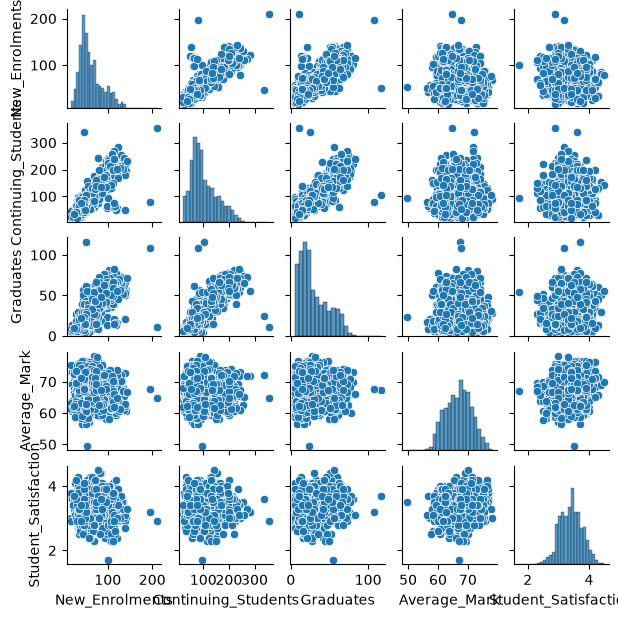

In [7]:
import seaborn as sns

sns.pairplot( df,  
              vars = ['New_Enrolments', 'Continuing_Students', 'Graduates', 'Average_Mark', 'Student_Satisfaction'],
              height = 1.25 )
plt.show()

In [8]:
print("First year", df["Year"].min())
print("Last year", df["Year"].max())

First year 2016
Last year 2025


## Can you find the minimum and maximum values of New_Enrolments?

In [10]:
print("Minimum New_Enrolments", df["New_Enrolments"].min())
print("Maximum New_Enrolments", df["New_Enrolments"].max())

Minimum New_Enrolments 17
Maximum New_Enrolments 210


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1016 entries, 0 to 1015
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  1016 non-null   int64  
 1   Programme             1015 non-null   str    
 2   Study_Mode            1013 non-null   str    
 3   New_Enrolments        1016 non-null   int64  
 4   Continuing_Students   1006 non-null   float64
 5   Graduates             1016 non-null   int64  
 6   Average_Mark          999 non-null    float64
 7   Student_Satisfaction  996 non-null    float64
dtypes: float64(3), int64(3), str(2)
memory usage: 82.7 KB


In [17]:
# Unique categorical Values
print("Programmes: ", df["Programme"].unique())
# paranthesis always used for functions
# [] used for arrays and dataframes
print("Study_Modes: ", df["Study_Mode"].unique())

Programmes:  <ArrowStringArray>
['Cybersecurity', 'Data Analytics', 'Business', 'Computing', nan]
Length: 5, dtype: str
Study_Modes:  <ArrowStringArray>
['Full-time', 'Part-time', 'Online', nan]
Length: 4, dtype: str


In [15]:
# Calcualte the presence of null values in the dataset
df.isnull().sum()

Year                     0
Programme                1
Study_Mode               3
New_Enrolments           0
Continuing_Students     10
Graduates                0
Average_Mark            17
Student_Satisfaction    20
dtype: int64

In [18]:
# Check the Duplicate values

print("Duplicate values: ", df.duplicated().sum())

Duplicate values:  11


In [19]:
# Remove the duplicated rows/ instances
df_analysis = df.drop_duplicates().copy()

print("Original number of rows: ", len(df))
print("After removing duplicated rows: ", len(df_analysis))

Original number of rows:  1016
After removing duplicated rows:  1005


In [20]:
print(df.dtypes)

Year                      int64
Programme                   str
Study_Mode                  str
New_Enrolments            int64
Continuing_Students     float64
Graduates                 int64
Average_Mark            float64
Student_Satisfaction    float64
dtype: object


In [21]:
# Categorical variables
categorical_columns = ['Programme', 'Study_Mode']

# Numeric variables
numeric_columns = ['Year', 'New_Enrolments', 'Continuing_Students', 'Graduates', 'Average_Mark', 'Student_Satisfaction']

print(categorical_columns)
print(numeric_columns)

['Programme', 'Study_Mode']
['Year', 'New_Enrolments', 'Continuing_Students', 'Graduates', 'Average_Mark', 'Student_Satisfaction']


In [22]:
# Replace missing values in the categorical columns
categorical_columns = df.select_dtypes(include = ["object", "str", "category"]).columns

for column in categorical_columns:
    df[column] = df[column].fillna( df[column].mode()[0] )

print(df.isnull().sum())

Year                     0
Programme                0
Study_Mode               0
New_Enrolments           0
Continuing_Students     10
Graduates                0
Average_Mark            17
Student_Satisfaction    20
dtype: int64


In [23]:
df['Continuing_Students'] = df['Continuing_Students'].fillna(df['Continuing_Students'].mean())
df['Average_Mark'] = df['Average_Mark'].fillna(df['Average_Mark'].mean())
df['Student_Satisfaction'] = df['Student_Satisfaction'].fillna(df['Student_Satisfaction'].median())

print(df.isnull().sum())

Year                    0
Programme               0
Study_Mode              0
New_Enrolments          0
Continuing_Students     0
Graduates               0
Average_Mark            0
Student_Satisfaction    0
dtype: int64


In [24]:
df.shape

(1016, 8)

In [25]:
df = df.drop_duplicates()
df.shape

(1005, 8)

In [26]:
df.to_csv("college_enrolment_cleaned.csv")

In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 1005 entries, 0 to 1015
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  1005 non-null   int64  
 1   Programme             1005 non-null   str    
 2   Study_Mode            1005 non-null   str    
 3   New_Enrolments        1005 non-null   int64  
 4   Continuing_Students   1005 non-null   float64
 5   Graduates             1005 non-null   int64  
 6   Average_Mark          1005 non-null   float64
 7   Student_Satisfaction  1005 non-null   float64
dtypes: float64(3), int64(3), str(2)
memory usage: 89.6 KB


In [28]:
annual_summary = (
    df.groupby("Year", as_index = False) [
        ["New_Enrolments", "Continuing_Students", "Graduates"]
    ].sum()
)

annual_summary["Total_students"] = ( annual_summary["New_Enrolments"] + annual_summary["Continuing_Students"] )
print(annual_summary)

   Year  New_Enrolments  Continuing_Students  Graduates  Total_students
0  2016            5335          8594.000000       2287    13929.000000
1  2017            5918          7813.000000       2266    13731.000000
2  2018            6236         10124.677932       2787    16360.677932
3  2019            6288         10408.000000       3198    16696.000000
4  2020            6594         11464.355865       3392    18058.355865
5  2021            7420         12607.355865       3537    20027.355865
6  2022            5933          9504.033797       2597    15437.033797
7  2023            7462         13386.000000       4202    20848.000000
8  2024            6009         10028.677932       2913    16037.677932
9  2025            5832          9153.677932       2505    14985.677932


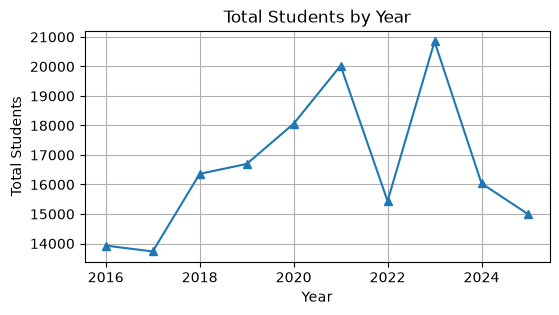

In [31]:
# First plot
plt.figure(figsize = (6, 3))

plt.plot(annual_summary["Year"], annual_summary["Total_students"], marker = '^')
plt.title("Total Students by Year")
plt.xlabel("Year")
plt.ylabel("Total Students")
plt.grid(True)
plt.show()

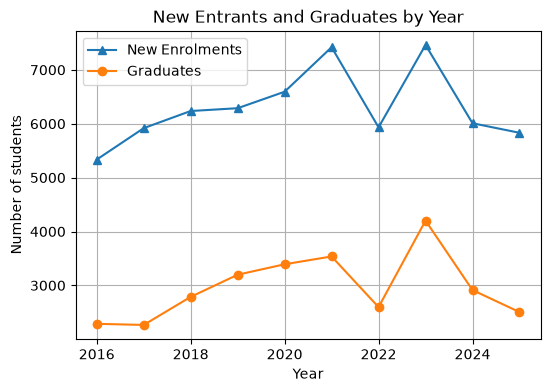

In [32]:
# First plot
plt.figure(figsize = (6, 4))

plt.plot(annual_summary["Year"], annual_summary["New_Enrolments"], label = "New Enrolments", marker = '^')
plt.plot(annual_summary["Year"], annual_summary["Graduates"], label = "Graduates", marker = 'o')

plt.title("New Entrants and Graduates by Year")
plt.xlabel("Year")
plt.ylabel("Number of students")

plt.legend()
plt.grid(True)
plt.show()

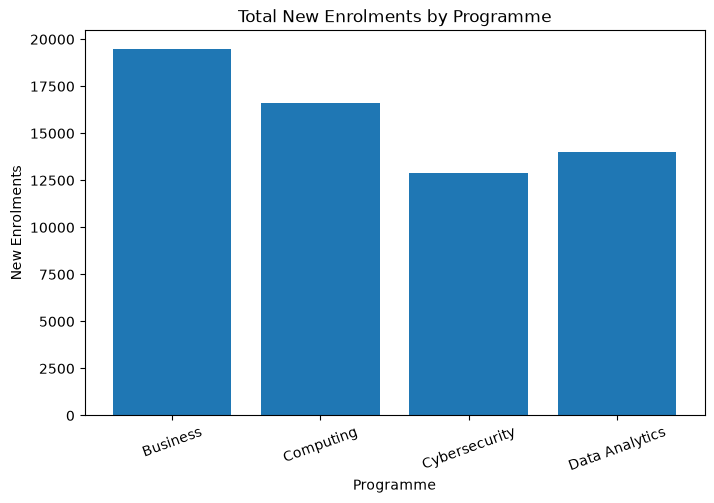

In [35]:
programme_enrolments = df.groupby('Programme')['New_Enrolments'].sum()

plt.figure(figsize = (8, 5))
plt.bar(programme_enrolments.index, programme_enrolments.values)

plt.title("Total New Enrolments by Programme")
plt.xlabel("Programme")
plt.ylabel("New Enrolments")

plt.xticks(rotation = 20)
plt.show()

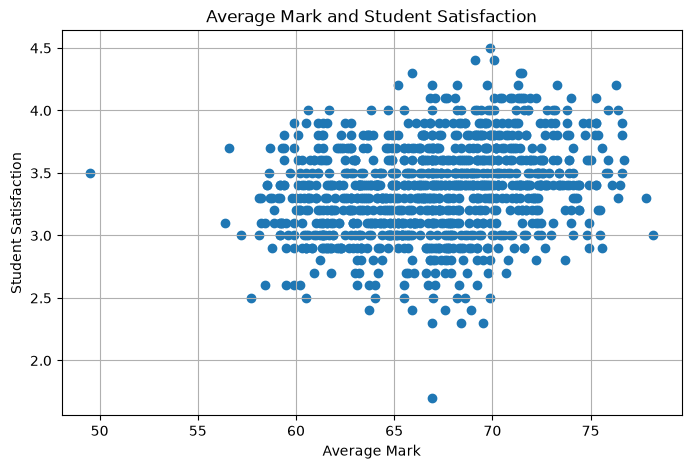

In [39]:
# relationship_data = df[ ['Average_Mark'], ['Student_Satisfaction'] ].dropna()

plt.figure(figsize  = (8, 5))
plt.scatter(df['Average_Mark'], df['Student_Satisfaction'])

plt.title("Average Mark and Student Satisfaction")
plt.xlabel("Average Mark")
plt.ylabel("Student Satisfaction")

plt.grid(True)
plt.show()

# Homework
## Use titanic dataset to analyse the data and perform the cleaning and plot the columns for the analysis.
* https://www.kaggle.com/datasets/yasserh/titanic-dataset